# Final Results: Dynamic Asset Allocation

## Research question

Do classical mean-variance optimization, Michaud resampling, and HRP improve out-of-sample risk-adjusted performance relative to transparent equal-weight and 60/40 benchmarks?

## Assignment requirements

The project implements naive benchmarks, Markowitz optimization, Michaud resampling, HRP, monthly out-of-sample rebalancing, a multi-asset ETF universe, transaction costs, turnover, performance tables, and figures.

## Data source and universe

The final comparison uses monthly adjusted ETF prices from Yahoo Finance for the 23-ETF core universe. The configured 27-ETF universe is documented separately; the extended 27-ETF panel is a descriptive data-policy robustness check rather than a complete optimized-strategy robustness backtest.

## Data inspection and sample policy

Raw data inspection showed structural pre-inception missingness for late-launch ETFs. No prices were interpolated, backfilled, or synthetically created. The final strategy comparison uses the common core-universe evaluation period from 2013-03-31 to 2026-05-31.

## Returns and estimators

Returns are monthly simple returns. The final table reports annualized geometric returns. Sharpe and Sortino ratios use annualized arithmetic mean excess returns, so Sharpe cannot be reconstructed directly from the displayed geometric-return column.

## Benchmarks

Equal Weight assigns 1/23 to every ETF. The 60/40 benchmark allocates 60% equally across equities and 40% equally across government bonds. Final benchmark metrics are recomputed on the common core period with the same 5 bps drift-aware transaction-cost convention used for optimized strategies.

## Markowitz methodology

Minimum-variance, maximum-Sharpe, and target-volatility portfolios are evaluated with sample covariance and Ledoit-Wolf covariance estimators. All optimized portfolios are long-only, fully invested, unleveraged, and capped at 25% per ETF.

## Michaud methodology

Michaud portfolios average constrained maximum-Sharpe solutions across 100, 250, or 500 simulated capital-market assumptions. The method is designed to reduce sensitivity to a single noisy efficient-frontier estimate.

## HRP extension

HRP avoids direct covariance inversion and allocates recursively through hierarchical clusters. In this universe, unconstrained HRP concentrated heavily in BIL, producing very low drawdown and turnover but weak excess performance and low effective diversification.

## Backtest timing

At rebalance date t, the rolling estimation window ends at t-1. The resulting weights are applied to the next realized month. This conservative one-month lag prevents contemporaneous information leakage.

## Transaction costs

Final results use the configured 5 bps one-way transaction cost and drift-aware turnover. Initial portfolio establishment is excluded from average turnover statistics.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TABLES = PROJECT_ROOT / 'outputs/tables'
FIGURES = PROJECT_ROOT / 'outputs/figures'

final_comparison = pd.read_csv(TABLES / 'final_strategy_comparison.csv')
final_comparison


                         strategy covariance_method  annualized_geometric_return  annualized_volatility  sharpe_ratio  sortino_ratio  max_drawdown  calmar_ratio  annualized_turnover  average_effective_number_of_assets  average_herfindahl_index  final_wealth
0                    Equal Weight               NaN                     0.060861               0.091145      0.475928       0.695311     -0.190655      0.319220             0.132286                           23.000000                  0.043478      2.187636
1                           60/40               NaN                     0.070122               0.097600      0.539989       0.812156     -0.233221      0.300666             0.124511                           13.888889                  0.072000      2.454646
2             Min Variance Sample            sample                     0.022498               0.027664      0.095817       0.128065     -0.080287      0.280226             0.260621                            4.712244         

## Final results

final_equity_curves.png
final_drawdowns.png
risk_return_scatter.png
turnover_vs_sharpe.png
diversification_vs_sharpe.png


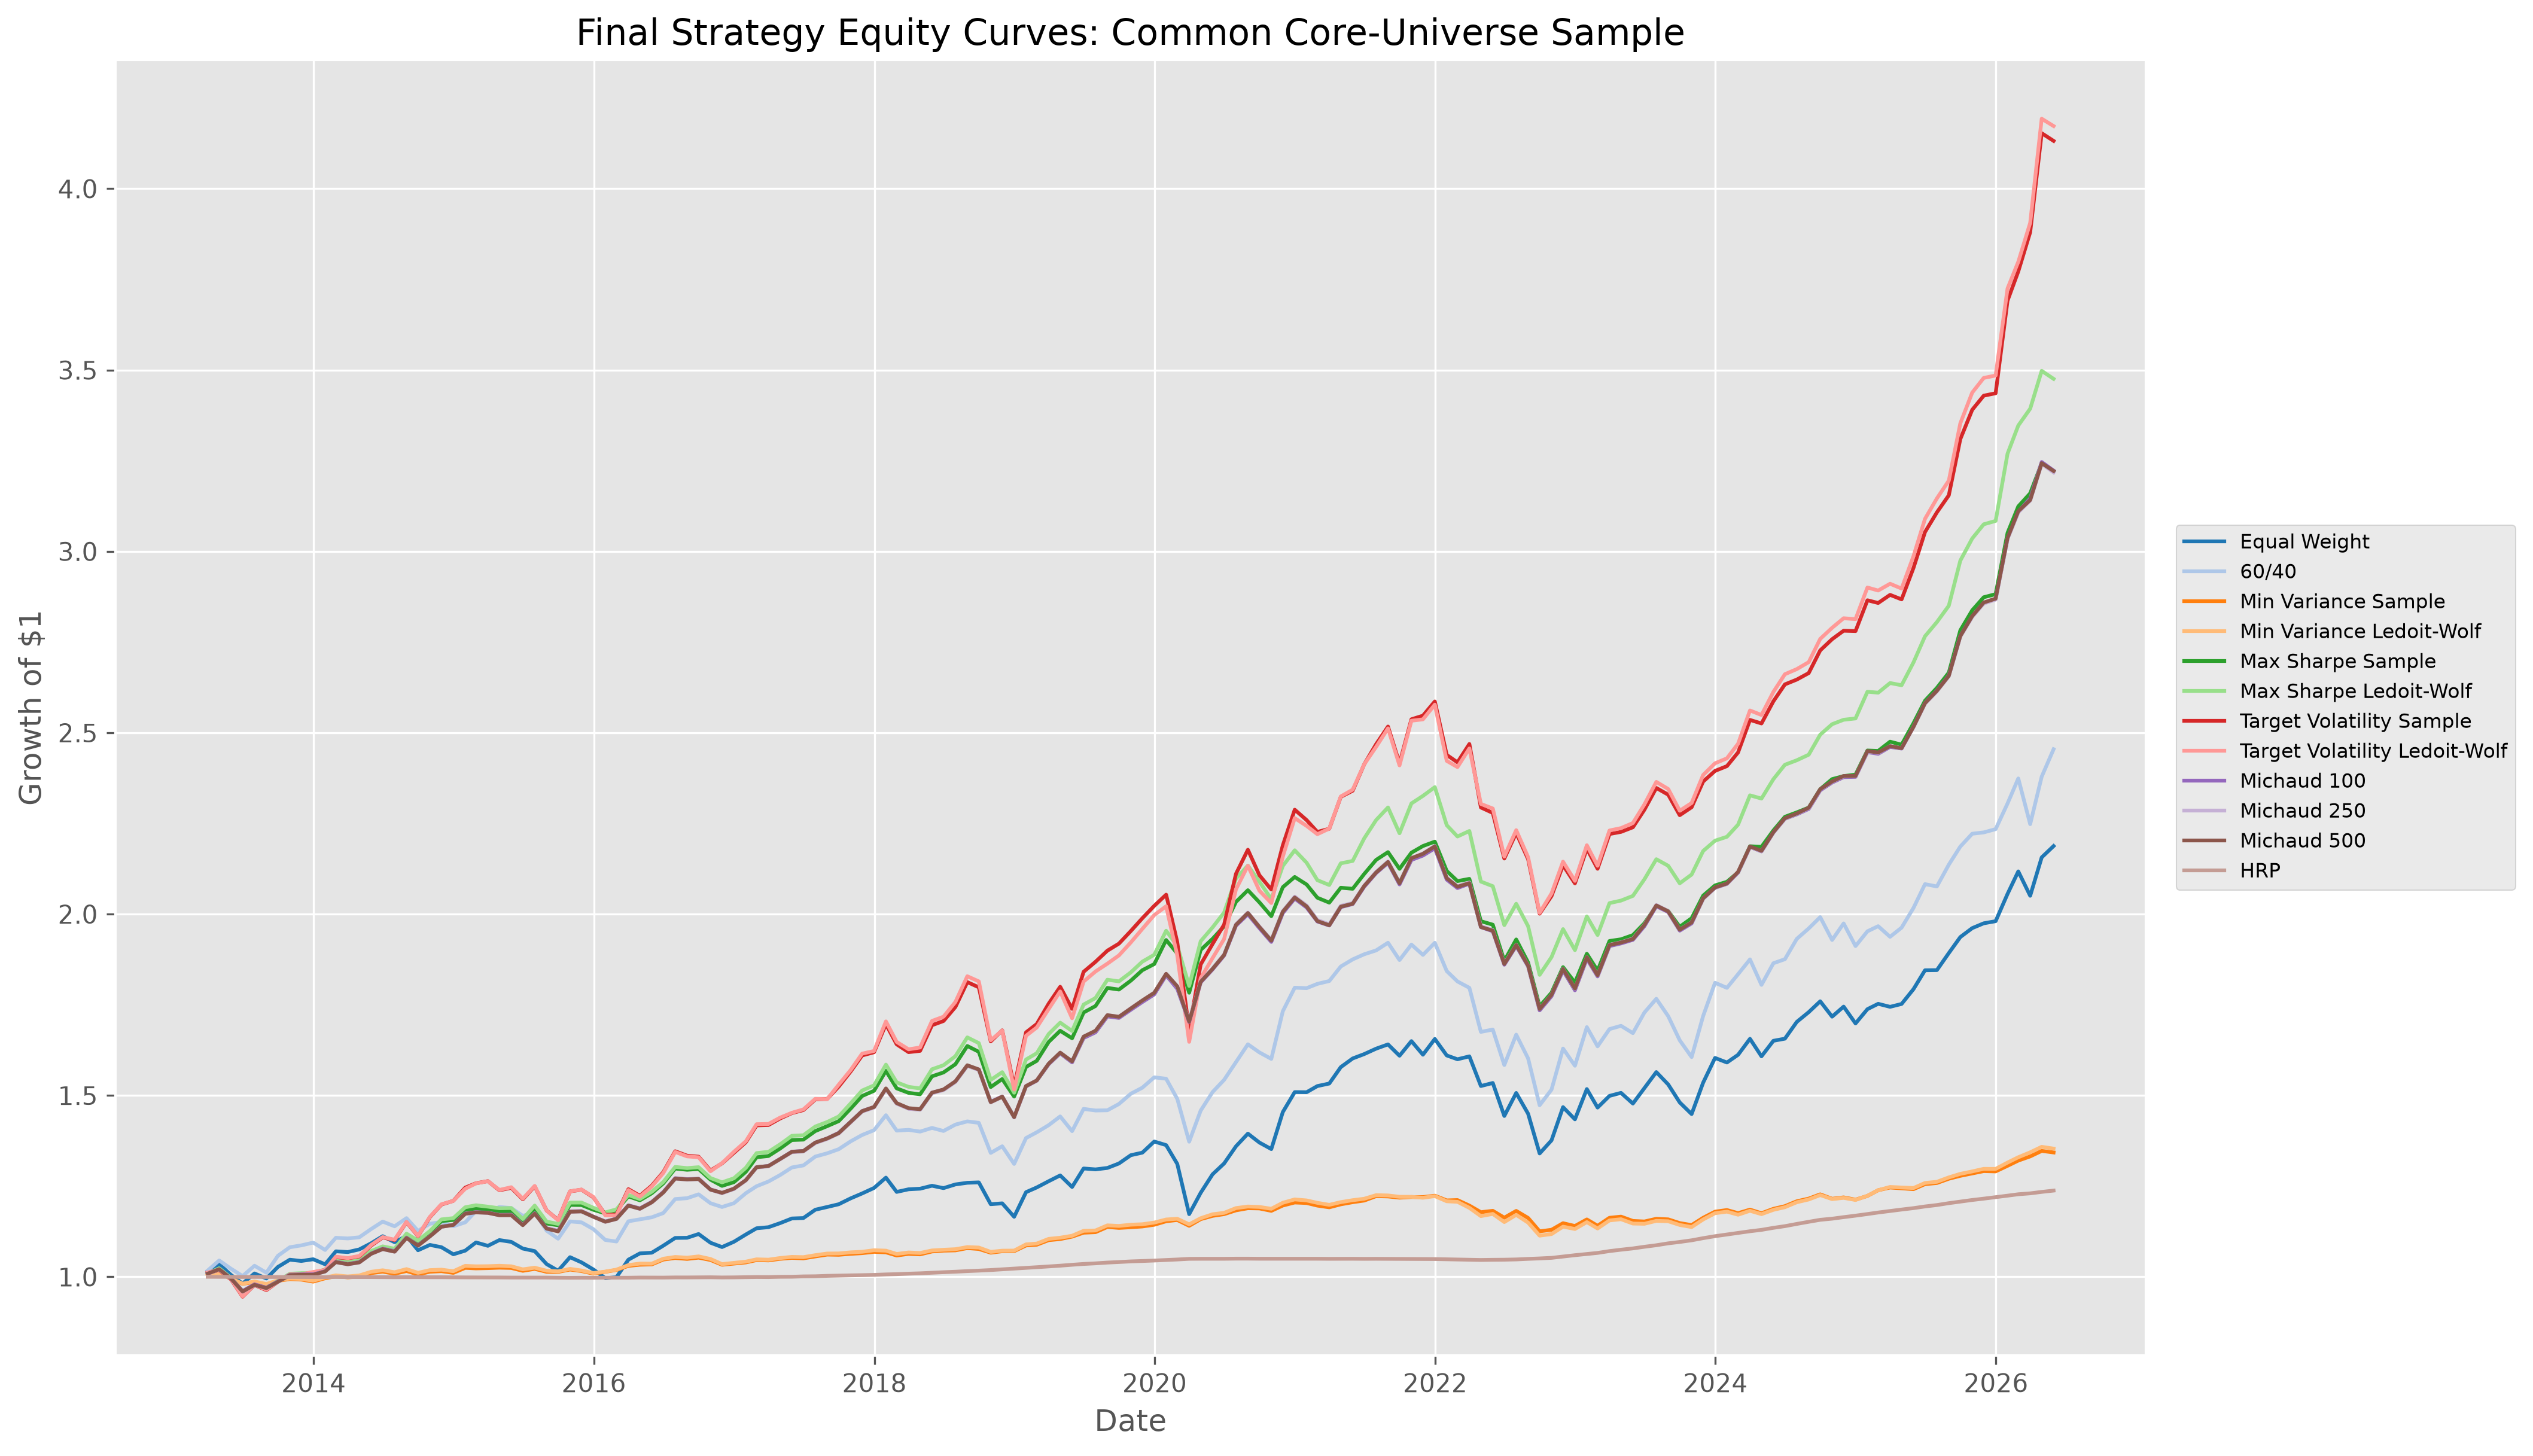

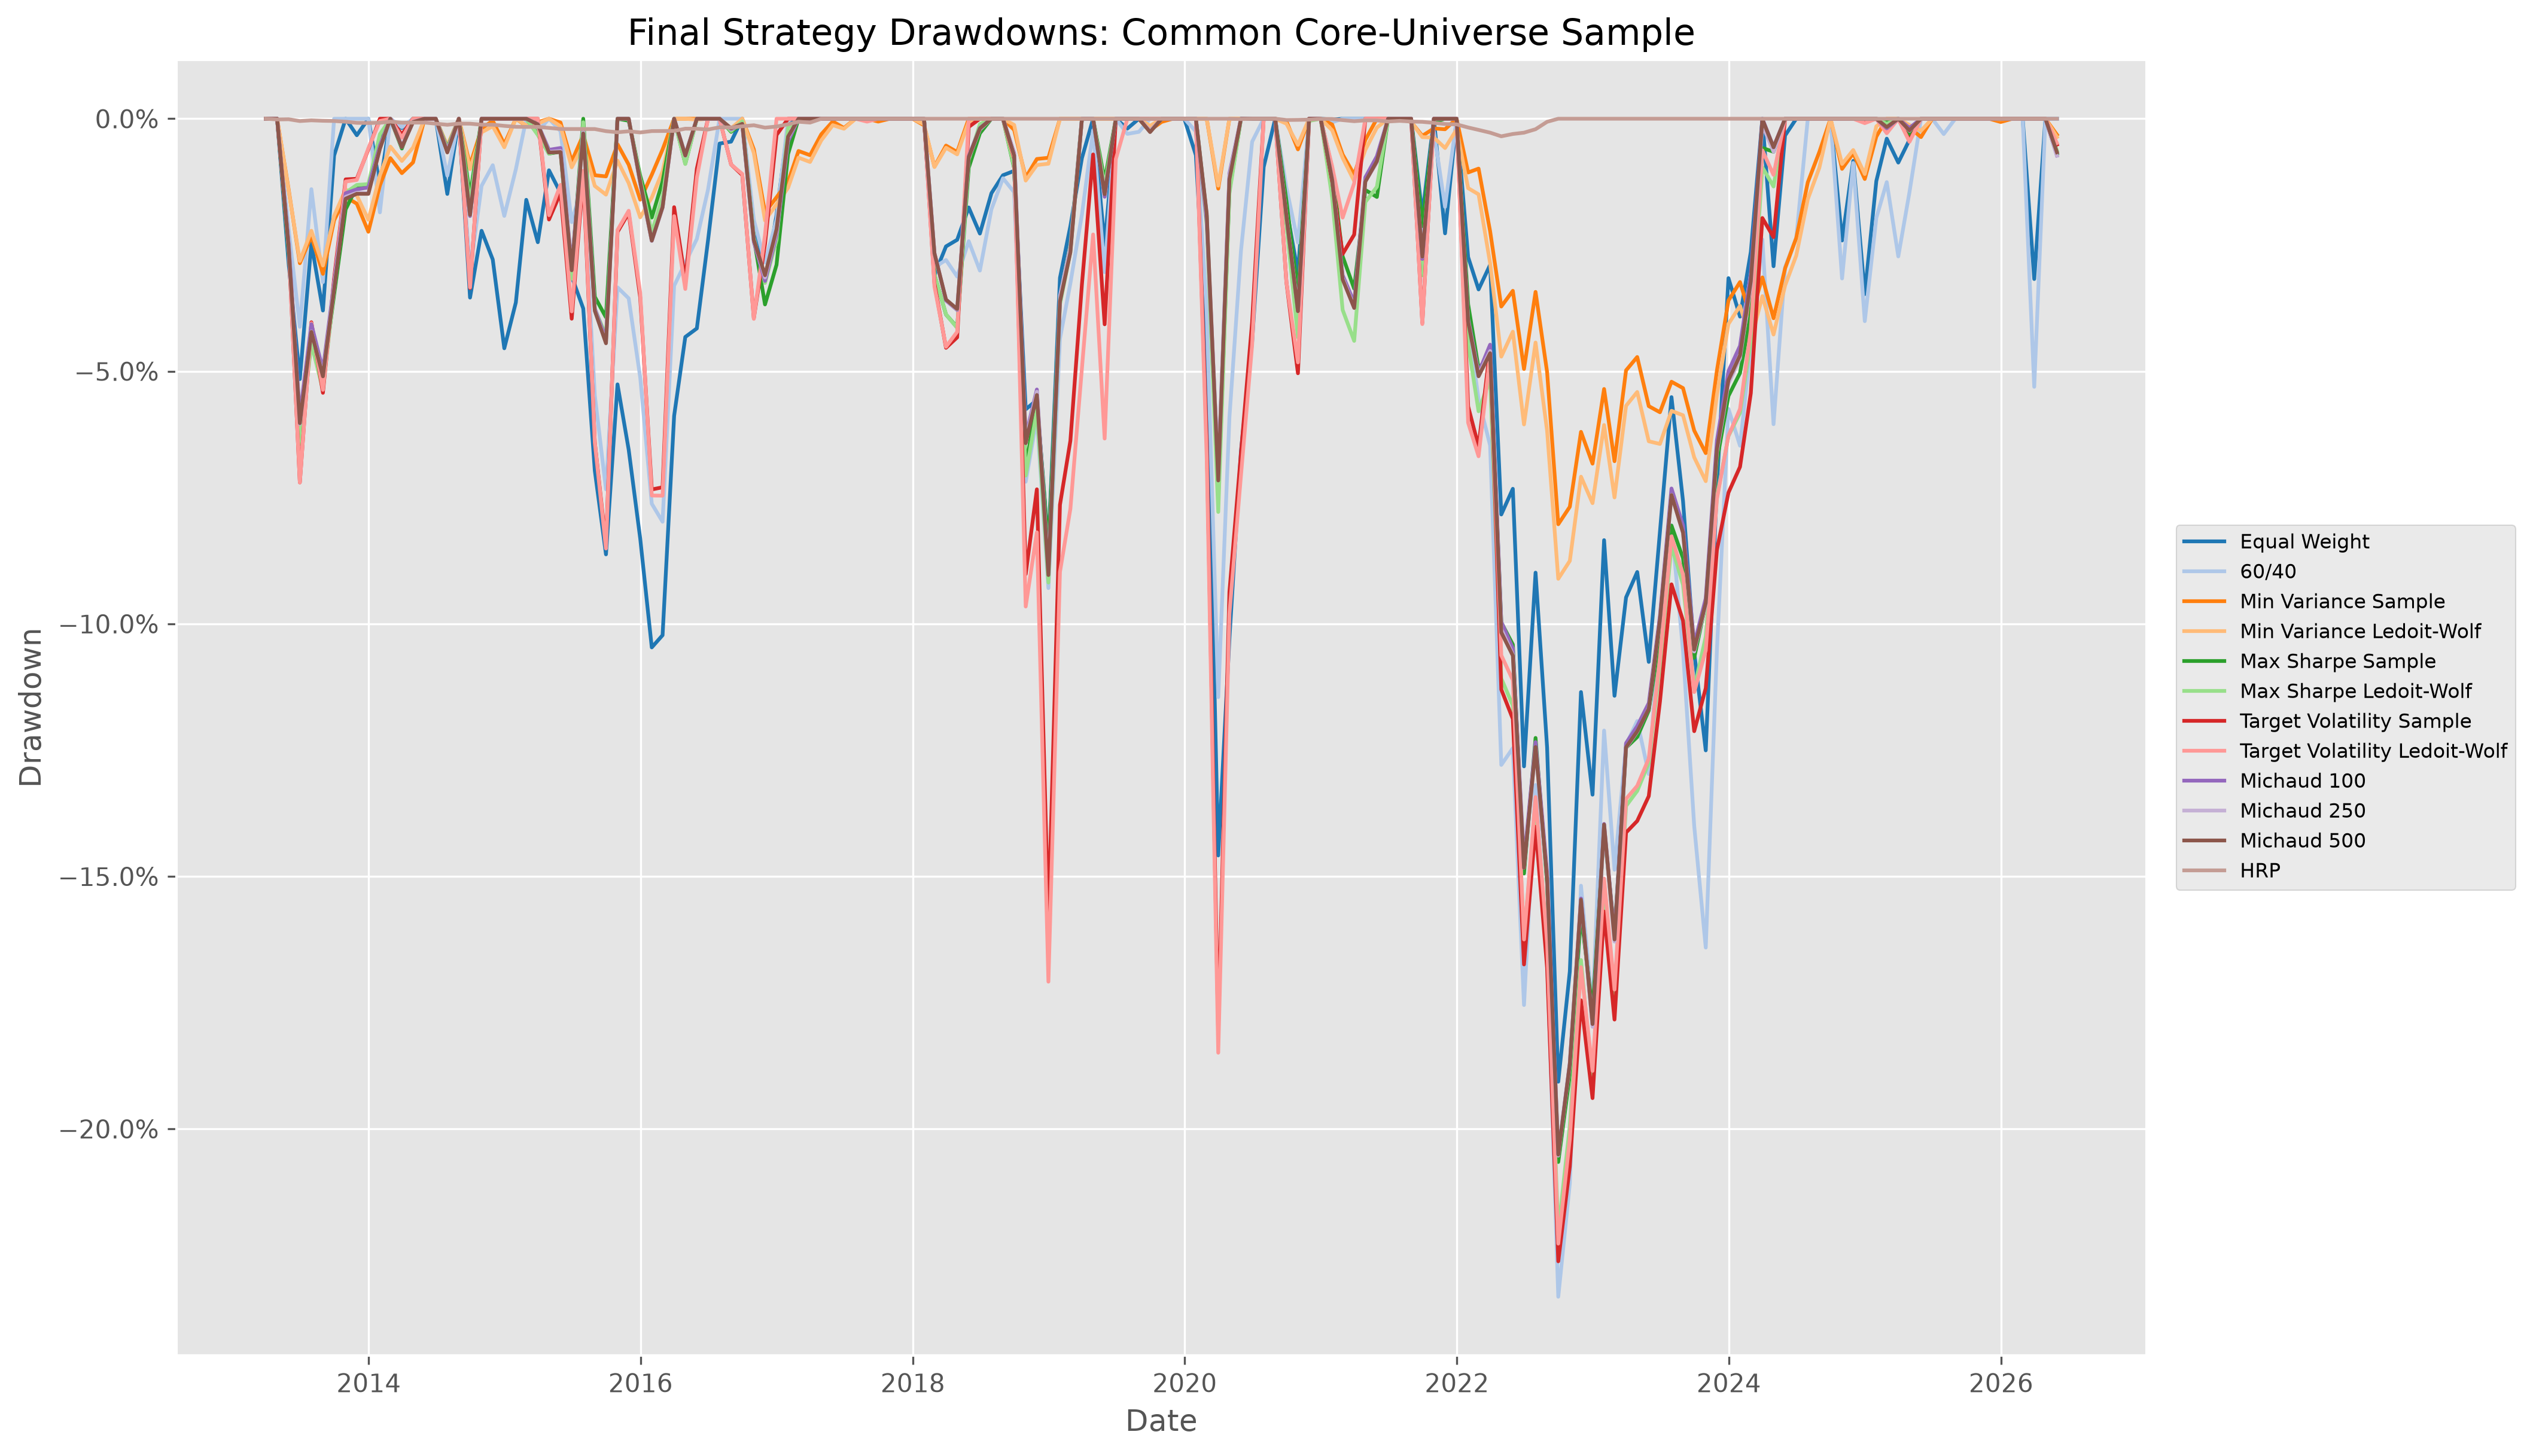

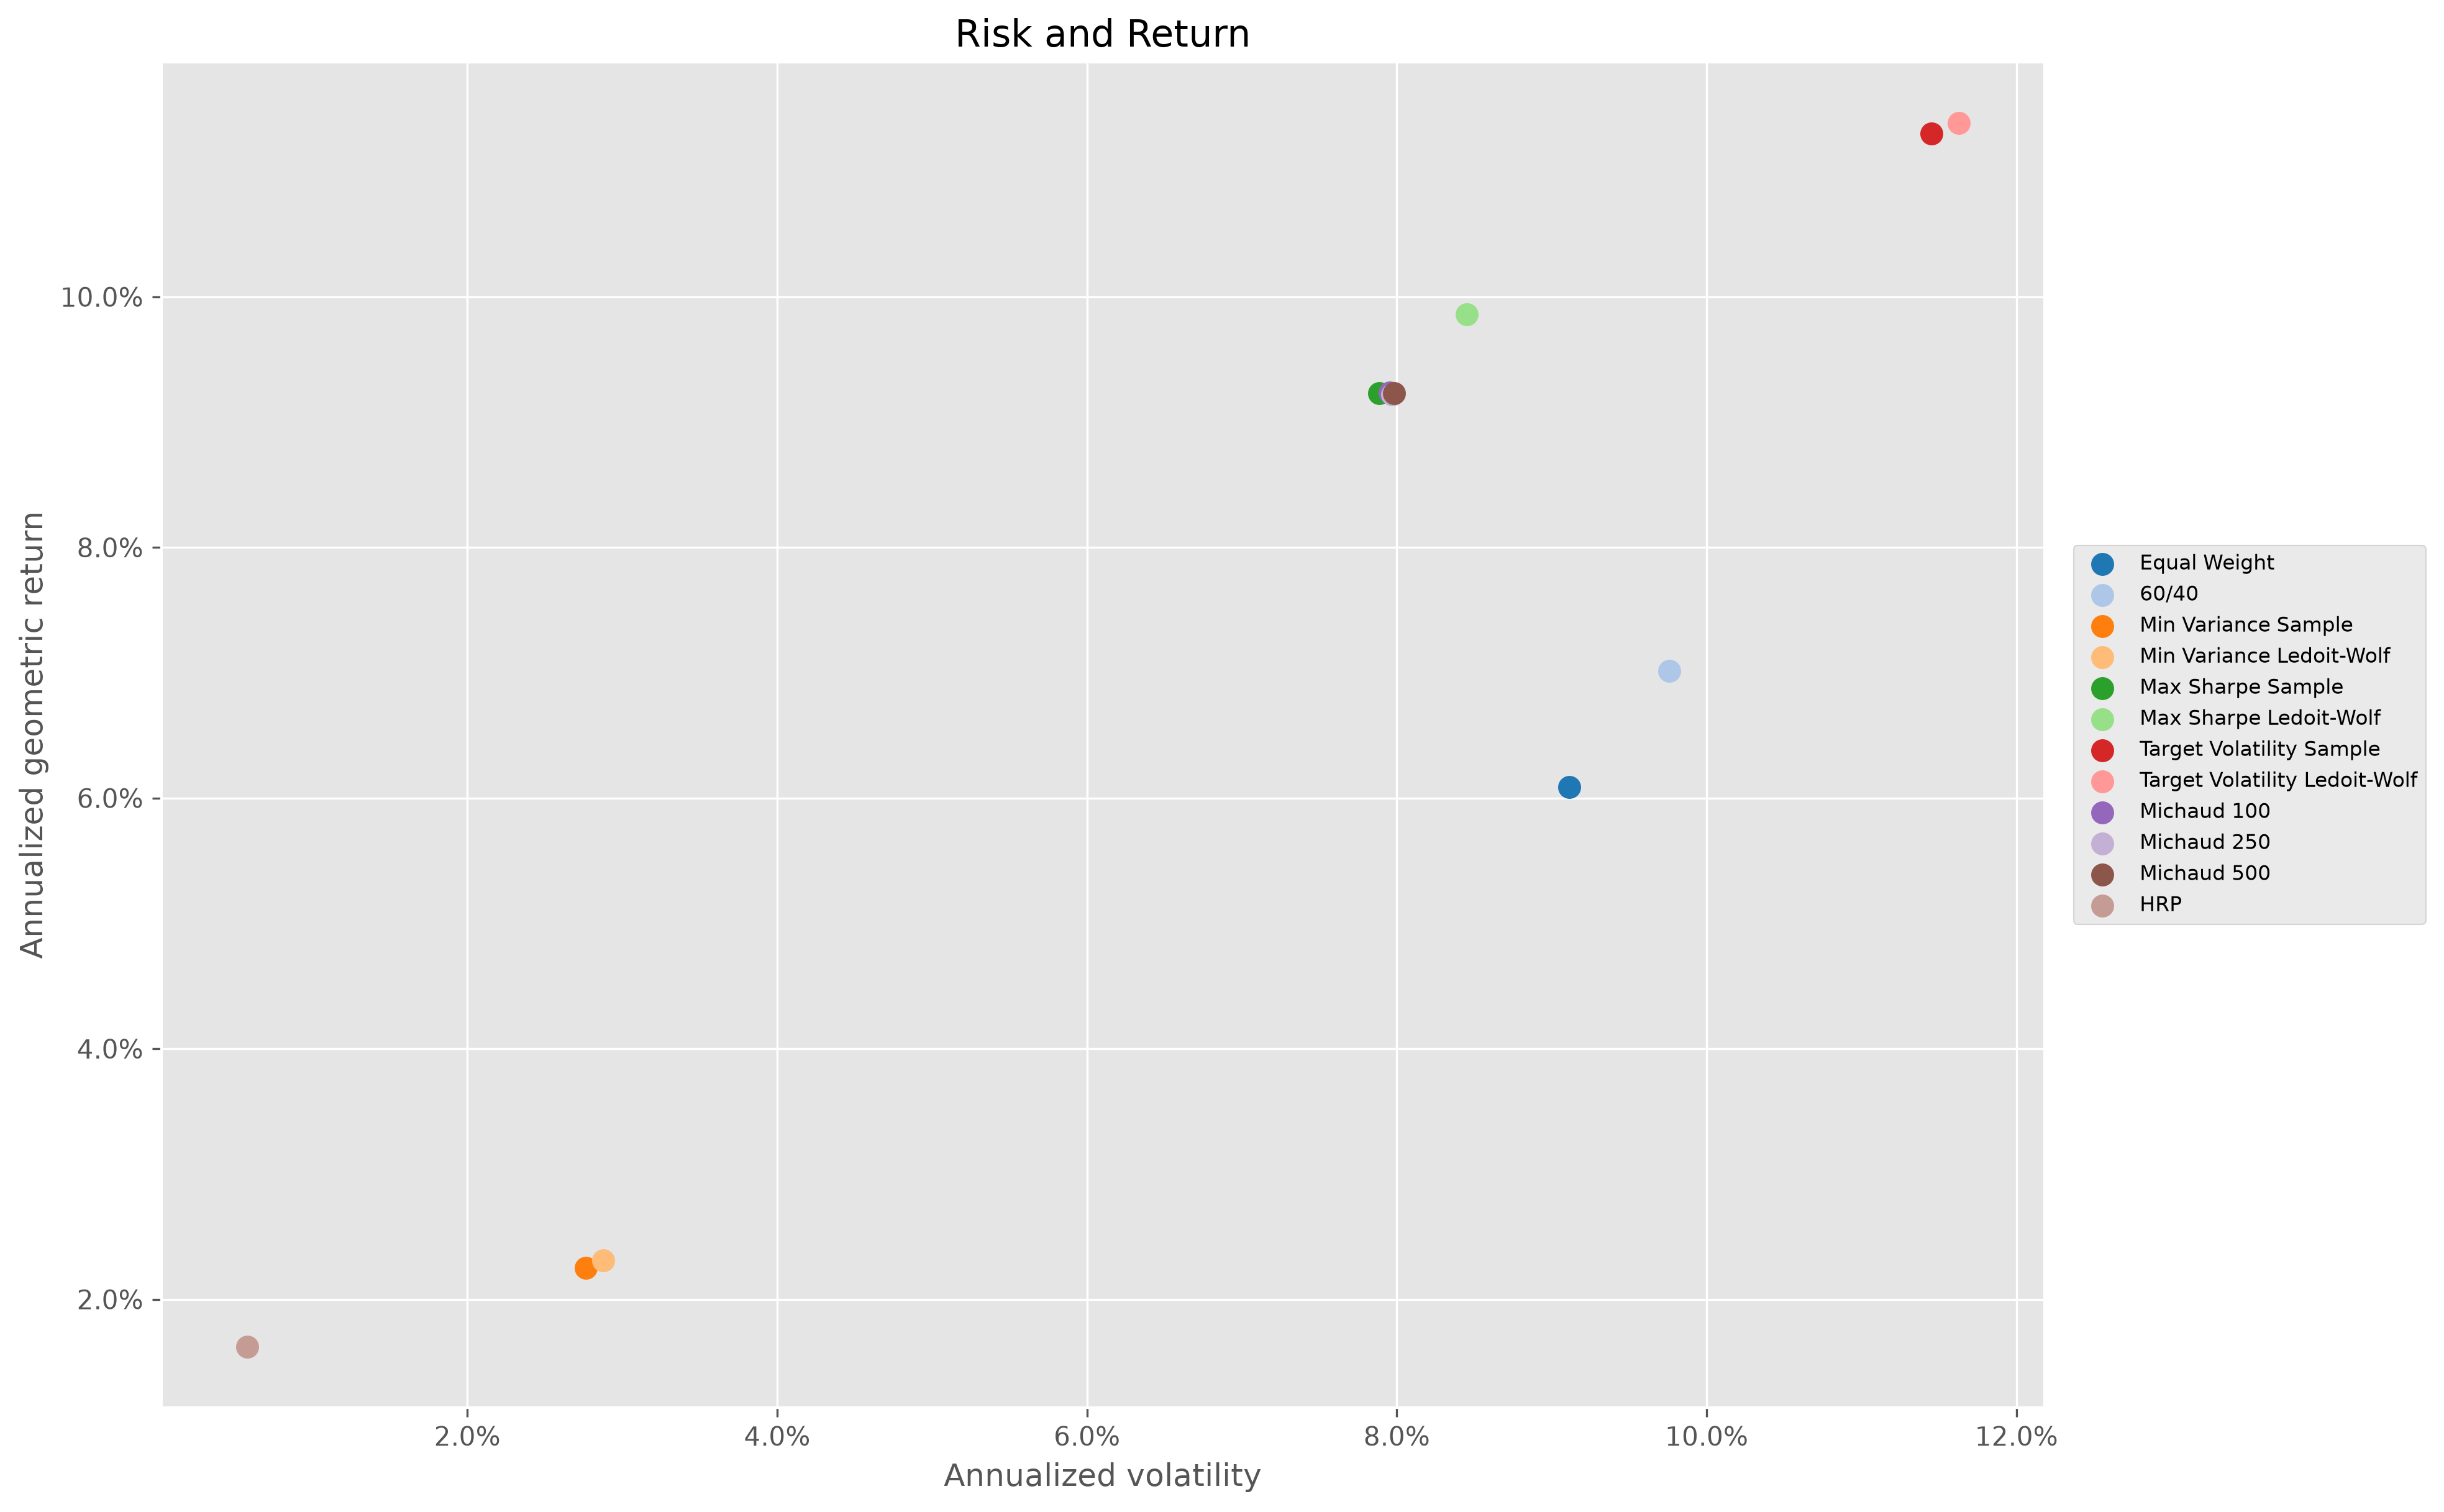

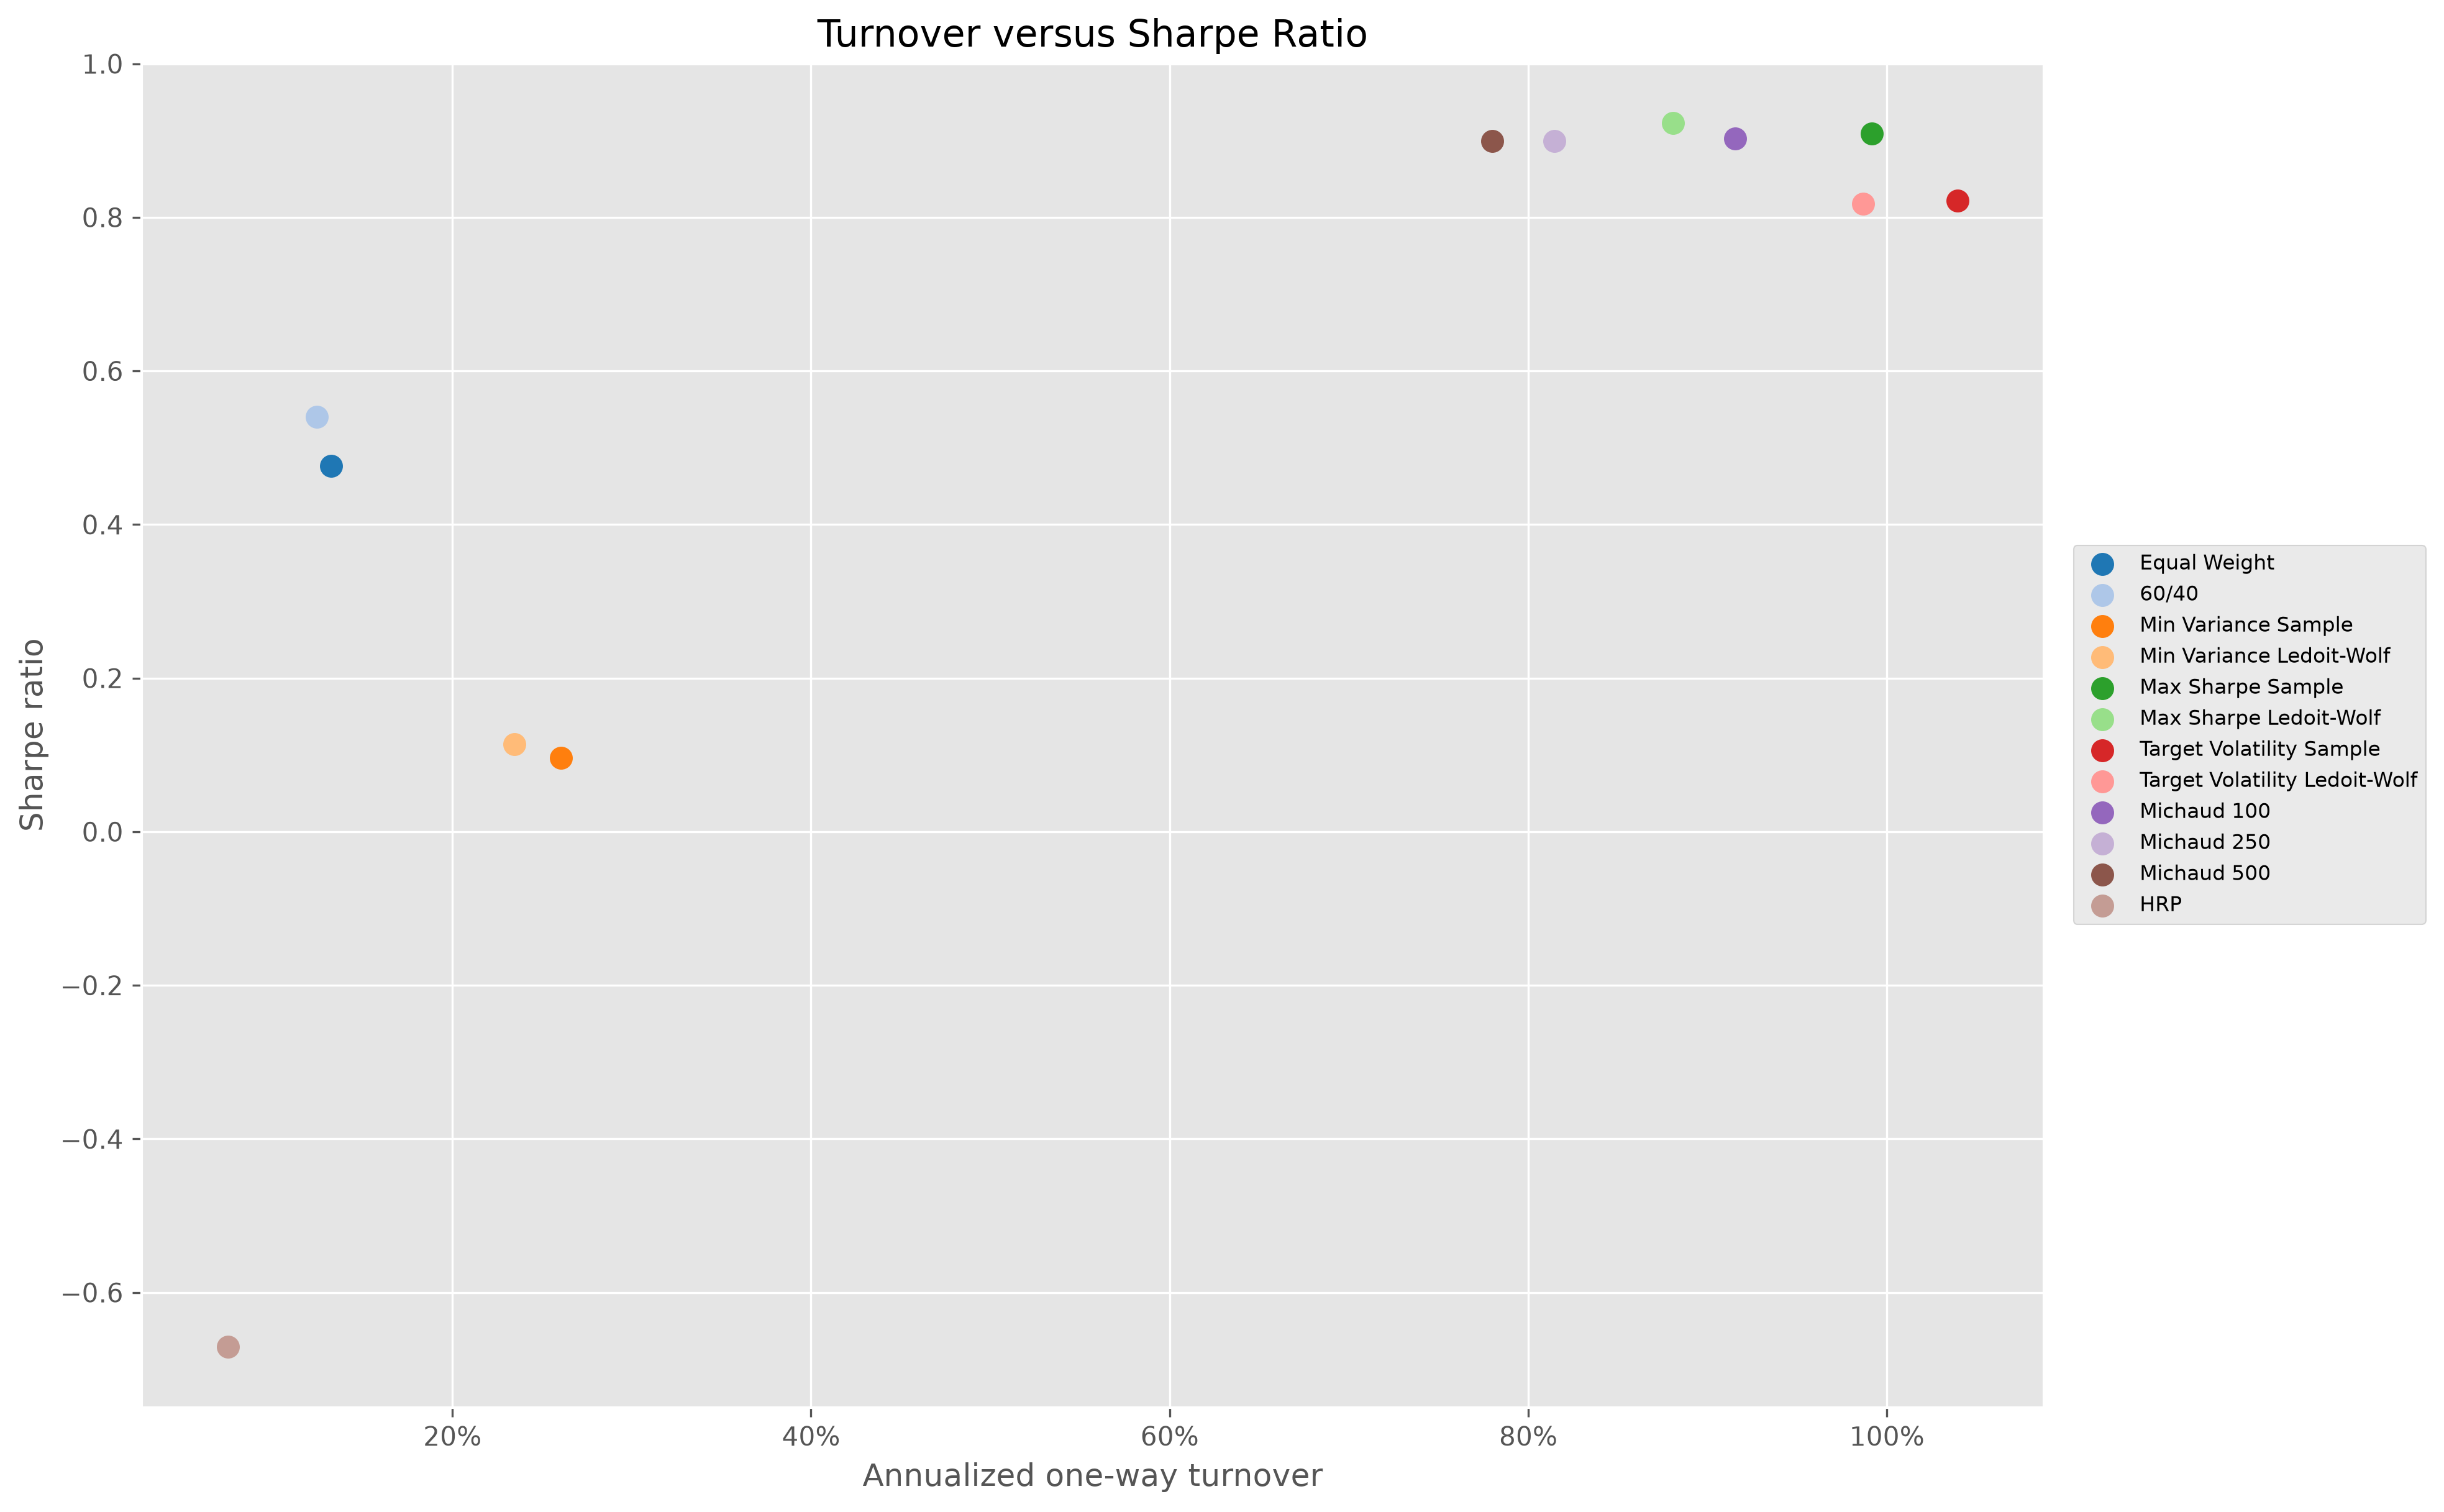

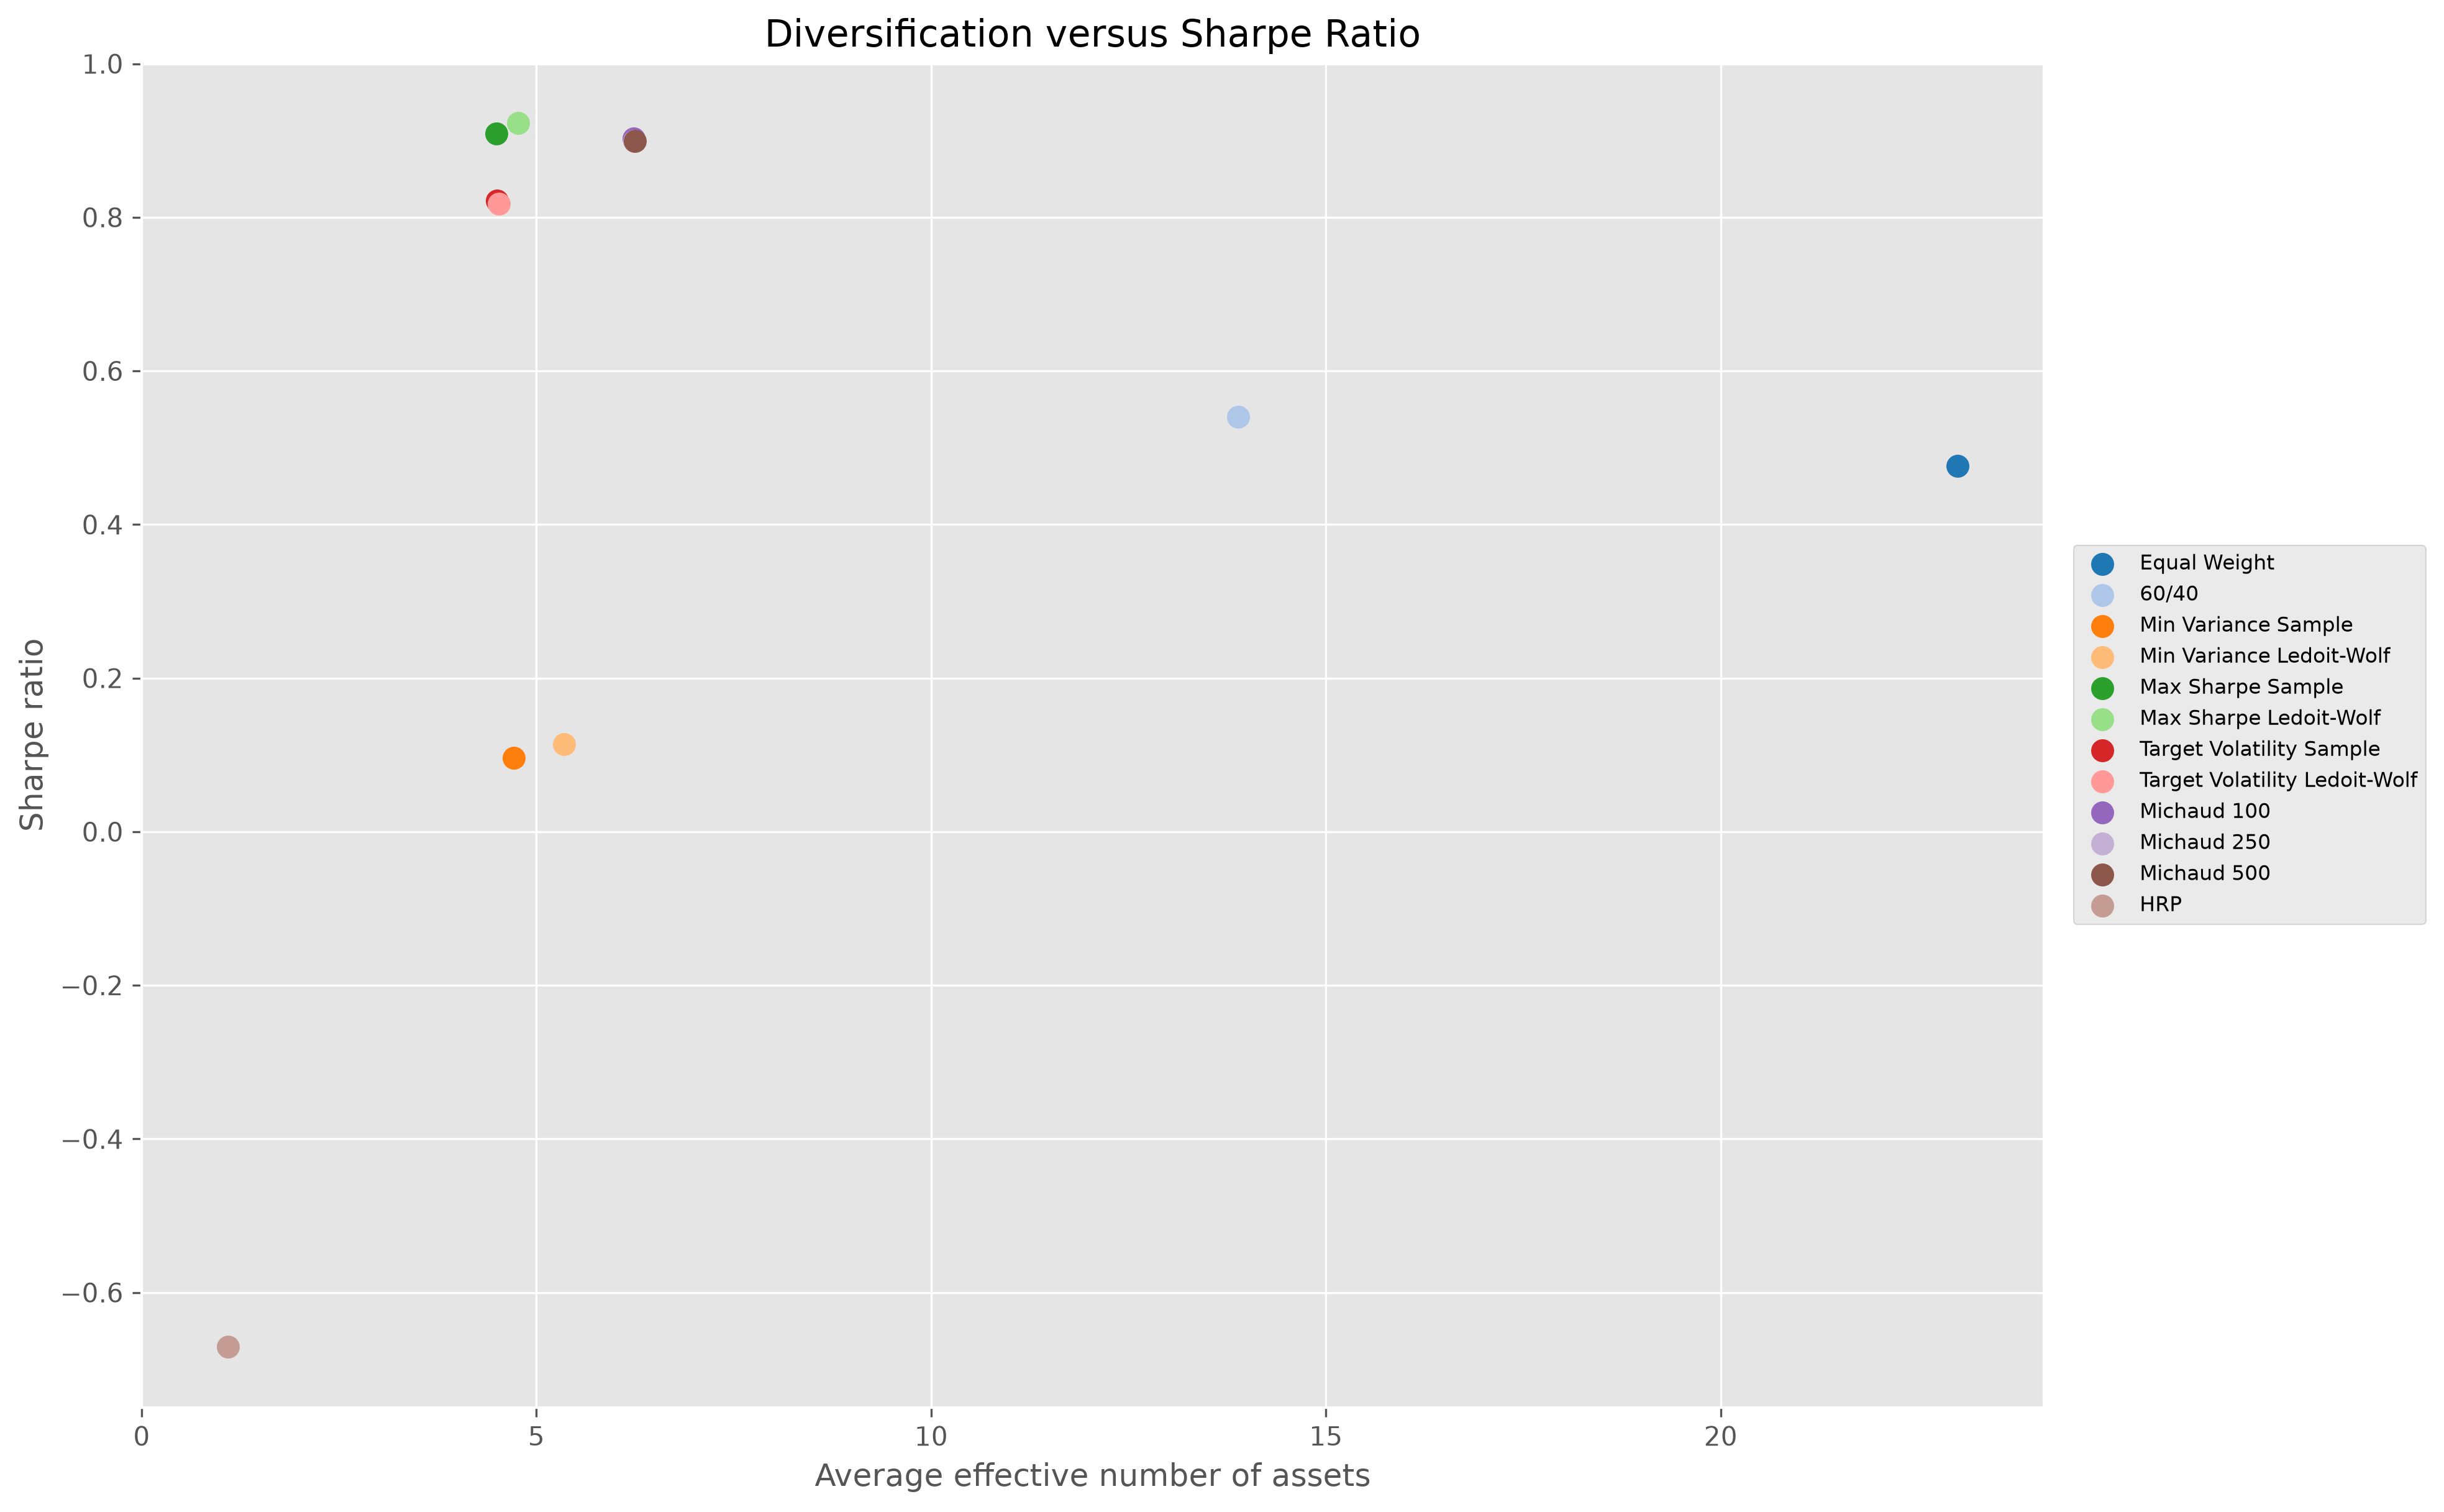

In [2]:
for figure_name in [
    'final_equity_curves.png',
    'final_drawdowns.png',
    'risk_return_scatter.png',
    'turnover_vs_sharpe.png',
    'diversification_vs_sharpe.png',
]:
    print(figure_name)
    display(Image(filename=str(FIGURES / figure_name)))


## Interpretation

Maximum Sharpe Ledoit-Wolf has the highest Sharpe ratio. Target Volatility Ledoit-Wolf has the highest terminal wealth and the strongest Calmar ratio among meaningful risk-bearing strategies. HRP has the numerically highest Calmar ratio only because its drawdown denominator is extremely small after concentrating in BIL. Michaud 500 improves turnover and effective diversification relative to Maximum Sharpe Ledoit-Wolf with only a small Sharpe reduction. Equal Weight has the highest effective number of assets by construction, so diversification comparisons are more meaningful among optimized strategies.

## Limitations

The analysis uses a fixed ETF universe, a constant risk-free rate and trading-cost assumption, one realized market path, and normally distributed Michaud simulations. Yahoo Finance adjusted prices are suitable for this academic project but are not an institutional total-return database. Small Sharpe differences should not be interpreted as proof of structural dominance.

## References

The methodology draws on Markowitz (1952), Michaud (1989), Michaud and Michaud (2008), Ledoit and Wolf (2004), L?pez de Prado (2016), DeMiguel, Garlappi, and Uppal (2009), and Idzorek (2005) for optional Black-Litterman future work. Full references are listed in `docs/references.md`.

## Conclusion with numeric findings

The final common-period table supports three main conclusions: Maximum Sharpe Ledoit-Wolf leads on Sharpe, Target Volatility Ledoit-Wolf leads on terminal wealth, and Michaud 500 offers a more diversified and lower-turnover optimized alternative with a modest Sharpe trade-off. HRP behaves as a defensive cash-concentrated allocation in this unconstrained universe.